# Safe Division and Diagonal Parameterization Sanity

**Objective.** Measure conversion error and compare diagonal `x/x`, `eps/eps`, and `v/v` image models.

**Training control.** Each model uses the same data batches, noise tensors, times, architecture, optimizer, and initialization seed.

**Sampling intervention.** Cross each training flag with both sampling flags. Use the same `z_init` for every condition.

**Expected result.** The safe-division flag does not change diagonal training. It can change `x` and `eps` sampling conversions.

In [1]:
# Purpose: Import the required packages and select one compute device.
from pathlib import Path
import json
import math
import sys
import time

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset

# Find the repository from either its root or the notebook directory.
REPO_ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "mem_param_src").is_dir()
)
sys.path.insert(0, str(REPO_ROOT))

from mem_param_src.config import clone_config, config_to_dict, get_base_config
from mem_param_src.datasets import build_data_bundle
from mem_param_src.metrics.image.memorization import compute_image_memorization_metrics
from mem_param_src.model import GDFM

RUN_DIR = REPO_ROOT / "outputs" / "experiments" / "safe_division_diagonal_sanity"
RUN_DIR.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"device: {device}")
print(f"run directory: {RUN_DIR}")

device: mps
run directory: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/experiments/safe_division_diagonal_sanity


In [2]:
# Purpose: Define the fixed data, model, training, and sampling protocol.
base_cfg = get_base_config()

base_cfg.study.name = "safe_division_diagonal_sanity"
base_cfg.study.dataset_key = "flowers102"
base_cfg.data.dataset = "flowers102"
base_cfg.data.root = str(REPO_ROOT / "data")
base_cfg.data.download = False
base_cfg.data.train_split = "train"
base_cfg.data.reference_split = "val"
base_cfg.data.n_train = 128
base_cfg.data.n_test = 64
base_cfg.data.image_size = 32
base_cfg.data.resize_size = 32
base_cfg.data.image_channels = 3
base_cfg.data.flatten = False

# Use the smallest valid two-level UNet from the runner prototype.
base_cfg.network.arch = "unet"
base_cfg.network.base_channels = 32
base_cfg.network.channel_mult = (1, 2)
base_cfg.network.attn_resolutions = ()
base_cfg.network.num_res_blocks = 1
base_cfg.network.dropout = 0.0

base_cfg.training.seed = 7
base_cfg.training.batch_size = 8
base_cfg.training.lr = 1.0e-3
base_cfg.training.weight_decay = 0.0
base_cfg.training.start_time = 0.01
base_cfg.training.end_time = 0.99
base_cfg.training.safe_div_denominator_floor = 0.01

base_cfg.sampling.method = "heun"
base_cfg.sampling.n_steps = 20
base_cfg.sampling.start_time = 0.01
base_cfg.sampling.end_time = 0.99
base_cfg.sampling.safe_div_denominator_floor = 0.01
base_cfg.sampling.output = "x_t_max"

SPACES = ("x", "eps", "v")
SAFE_DIVISION_MODES = (("exact", False), ("safe", True))
N_TRAINING_STEPS = 100
CHECKPOINT_STEPS = (0, 25, 50, 100)
N_SAMPLES = 16
SAFE_DIV_DENOM_EPS = 0.01
MODEL_SEED = 101

protocol = {
    "diagonal_spaces": SPACES,
    "N": int(base_cfg.data.n_train),
    "reference_N": int(base_cfg.data.n_test),
    "batch_size": int(base_cfg.training.batch_size),
    "training_steps": N_TRAINING_STEPS,
    "learning_rate": float(base_cfg.training.lr),
    "training_time": (float(base_cfg.training.start_time), float(base_cfg.training.end_time)),
    "sampling_steps": int(base_cfg.sampling.n_steps),
    "training_use_safe_div": [False, True],
    "sampling_use_safe_div": [False, True],
    "safe_div_denominator_floor": SAFE_DIV_DENOM_EPS,
}
protocol

{'diagonal_spaces': ('x', 'eps', 'v'),
 'N': 128,
 'reference_N': 64,
 'batch_size': 8,
 'training_steps': 100,
 'learning_rate': 0.001,
 'training_time': (0.01, 0.99),
 'sampling_steps': 20,
 'training_use_safe_div': [False, True],
 'sampling_use_safe_div': [False, True],
 'safe_div_denominator_floor': 0.01}

In [3]:
# Purpose: Load Flowers102 and create one fixed training schedule for all models.
bundle = build_data_bundle(base_cfg)
train_tensor = bundle["train"]
reference_tensor = bundle["reference"]

assert train_tensor.shape == (128, 3, 32, 32)
assert reference_tensor.shape == (64, 3, 32, 32)

# DataLoader supplies deterministic shuffled batches without augmentation.
loader_generator = torch.Generator().manual_seed(202)
train_loader = DataLoader(
    TensorDataset(train_tensor),
    batch_size=int(base_cfg.training.batch_size),
    shuffle=True,
    drop_last=True,
    generator=loader_generator,
    num_workers=0,
)

training_batches = []
while len(training_batches) < N_TRAINING_STEPS:
    for (batch,) in train_loader:
        training_batches.append(batch.clone())
        if len(training_batches) == N_TRAINING_STEPS:
            break
training_batches = torch.stack(training_batches)

# Use the same noise and time for every diagonal parameterization.
noise_generator = torch.Generator().manual_seed(303)
time_generator = torch.Generator().manual_seed(404)
training_noise = torch.randn(training_batches.shape, generator=noise_generator)
training_times = torch.rand(
    N_TRAINING_STEPS,
    int(base_cfg.training.batch_size),
    generator=time_generator,
)
training_times = (
    training_times
    * (float(base_cfg.training.end_time) - float(base_cfg.training.start_time))
    + float(base_cfg.training.start_time)
)

z_generator = torch.Generator().manual_seed(505)
z_init = torch.randn(N_SAMPLES, 3, 32, 32, generator=z_generator)

# Save every stochastic input required to replay this sanity experiment.
torch.save(bundle, RUN_DIR / "data_bundle.pt")
torch.save(
    {
        "training_batches": training_batches,
        "training_noise": training_noise,
        "training_times": training_times,
    },
    RUN_DIR / "training_schedule.pt",
)
torch.save(z_init, RUN_DIR / "z_init.pt")
(RUN_DIR / "base_config.json").write_text(
    json.dumps(config_to_dict(base_cfg), indent=2) + "\n",
    encoding="utf-8",
)

print(f"training schedule: {tuple(training_batches.shape)}")
print(f"training time range: {float(training_times.min()):.6f} to {float(training_times.max()):.6f}")
print(f"fixed z_init: {tuple(z_init.shape)}")

training schedule: (100, 8, 3, 32, 32)
training time range: 0.010960 to 0.987904
fixed z_init: (16, 3, 32, 32)


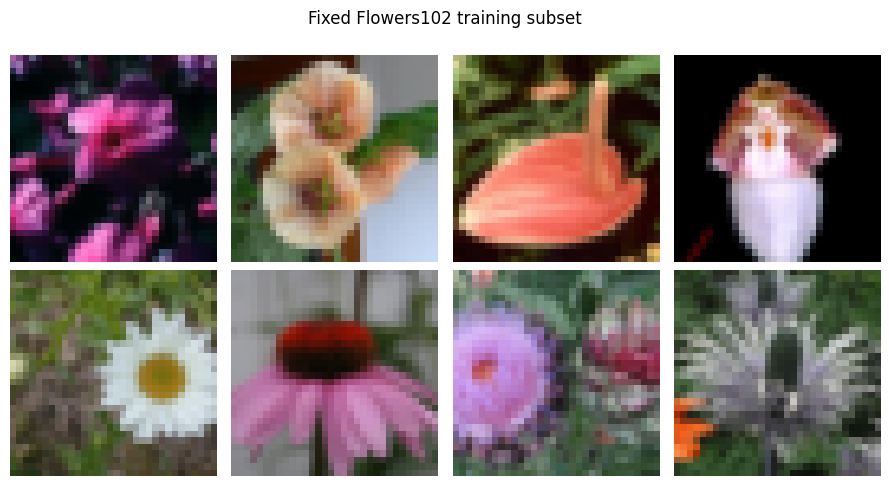

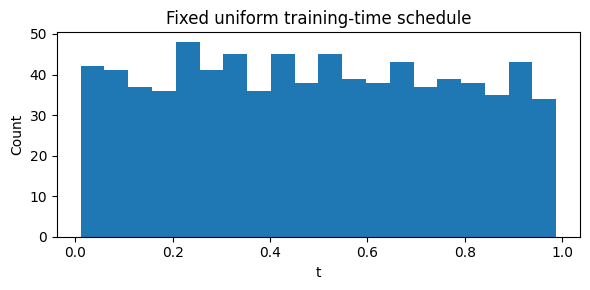

In [4]:
# Purpose: Inspect the training subset and sampled training times.
display_images = train_tensor[:8].add(1.0).div(2.0).clamp(0.0, 1.0)

figure, axes = plt.subplots(2, 4, figsize=(9, 5))
for index, axis in enumerate(axes.flatten()):
    axis.imshow(display_images[index].permute(1, 2, 0))
    axis.axis("off")
figure.suptitle("Fixed Flowers102 training subset")
figure.tight_layout()
figure.savefig(RUN_DIR / "training_examples.png", dpi=150, bbox_inches="tight")
plt.show()

time_figure, time_axis = plt.subplots(figsize=(6, 3))
time_axis.hist(training_times.flatten().numpy(), bins=20)
time_axis.set_xlabel("t")
time_axis.set_ylabel("Count")
time_axis.set_title("Fixed uniform training-time schedule")
time_figure.tight_layout()
time_figure.savefig(RUN_DIR / "training_times.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Purpose: Measure all six conversion errors across time and epsilon values.
conversion_cfg = get_base_config()
conversion_cfg.network.arch = "mlp"
conversion_cfg.data.data_dim = 4
conversion_cfg.framework.prediction_space = "x"
conversion_cfg.framework.loss_space = "x"
conversion_model = GDFM(conversion_cfg)

time_values = torch.tensor(
    [
        1.0e-6, 1.0e-5, 1.0e-4, 1.0e-3, 0.005, 0.01, 0.02, 0.05,
        0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.98, 0.99, 0.995,
        0.999, 0.9999, 0.99999, 0.999999,
    ],
    dtype=torch.float64,
)
EPSILON_VALUES = (1.0e-6, 1.0e-4, 1.0e-3, 1.0e-2, 5.0e-2)
CONVERSIONS = (
    ("x", "eps"),
    ("x", "v"),
    ("eps", "x"),
    ("eps", "v"),
    ("v", "x"),
    ("v", "eps"),
)

truth_generator = torch.Generator().manual_seed(606)
x_base = torch.randn(len(time_values), 4096, generator=truth_generator, dtype=torch.float64)
eps_base = torch.randn(len(time_values), 4096, generator=truth_generator, dtype=torch.float64)
conversion_errors = {}

for dtype in (torch.float32, torch.float64):
    dtype_name = str(dtype).split(".")[-1]
    t = time_values.to(dtype)
    x = x_base.to(dtype)
    eps = eps_base.to(dtype)
    z_t = t[:, None] * x + (1.0 - t[:, None]) * eps
    v = x - eps  # Linear FM gives v = x - eps.
    values = {"x": x, "eps": eps, "v": v}

    for source, target in CONVERSIONS:
        exact = conversion_model.convert(
            values[source],
            z_t,
            t,
            source=source,
            target=target,
            use_safe_div=False,
            safe_div_denominator_floor=SAFE_DIV_DENOM_EPS,
        )
        exact_error = (exact - values[target]).square().mean(dim=1).sqrt().cpu()
        conversion_errors[(dtype_name, source, target, "exact")] = exact_error

        for epsilon in EPSILON_VALUES:
            safe = conversion_model.convert(
                values[source],
                z_t,
                t,
                source=source,
                target=target,
                use_safe_div=True,
                safe_div_denominator_floor=epsilon,
            )
            safe_error = (safe - values[target]).square().mean(dim=1).sqrt().cpu()
            conversion_errors[(dtype_name, source, target, epsilon)] = safe_error

assert all(torch.isfinite(error).all() for error in conversion_errors.values())
print(f"conversion result vectors: {len(conversion_errors)}")
print("all conversion errors are finite")

conversion result vectors: 72
all conversion errors are finite


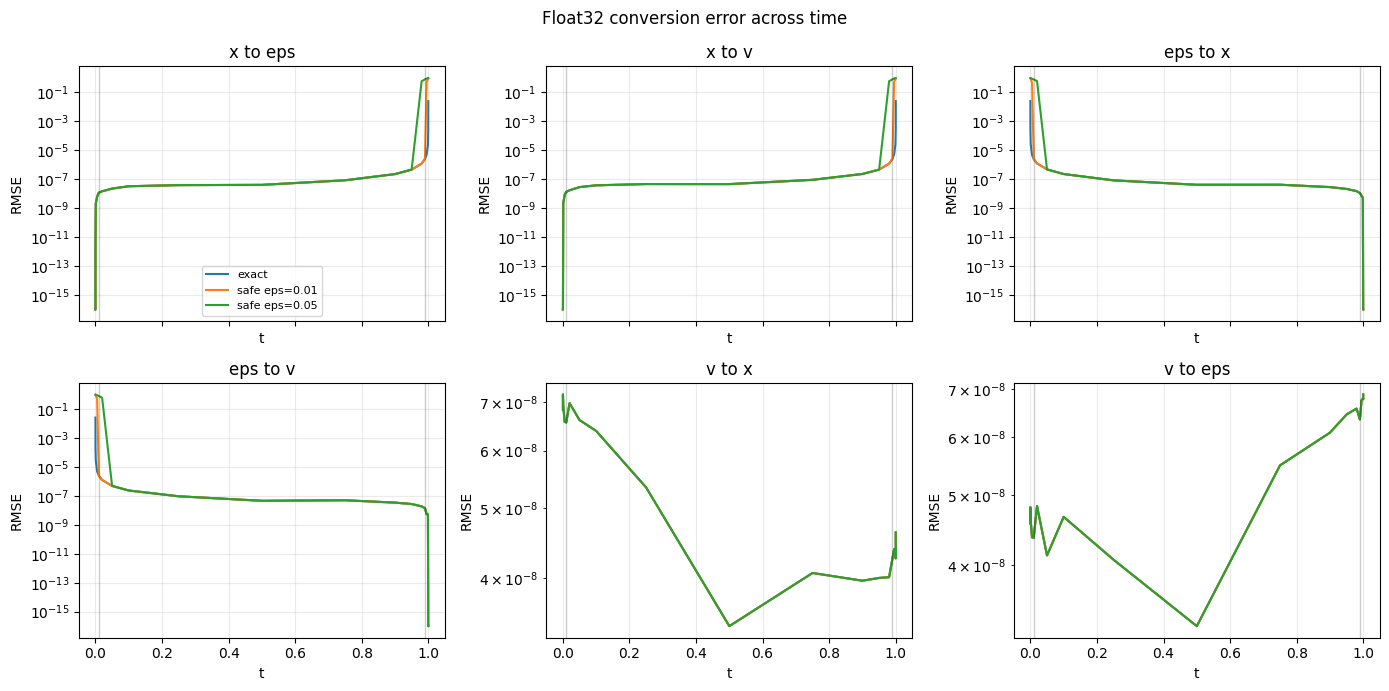

[{'conversion': 'x->eps',
  'exact': 2.4927301183197415e-06,
  'safe_0.01': 2.6655472993297735e-06,
  'safe_0.05': 0.8036976456642151},
 {'conversion': 'x->v',
  'exact': 2.4927464892243734e-06,
  'safe_0.01': 2.6651418920664582e-06,
  'safe_0.05': 0.8036976456642151},
 {'conversion': 'eps->x',
  'exact': 2.5175374958053e-06,
  'safe_0.01': 2.5175374958053e-06,
  'safe_0.05': 0.793484091758728},
 {'conversion': 'eps->v',
  'exact': 2.5178881060128333e-06,
  'safe_0.01': 2.5178881060128333e-06,
  'safe_0.05': 0.793484091758728},
 {'conversion': 'v->x',
  'exact': 6.978255129297395e-08,
  'safe_0.01': 6.978255129297395e-08,
  'safe_0.05': 6.978255129297395e-08},
 {'conversion': 'v->eps',
  'exact': 6.573156241529432e-08,
  'safe_0.01': 6.573156241529432e-08,
  'safe_0.05': 6.573156241529432e-08}]

In [6]:
# Purpose: Plot float32 conversion error and summarize the configured time interval.
error_figure, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)

for axis, (source, target) in zip(axes.flatten(), CONVERSIONS):
    axis.semilogy(
        time_values,
        conversion_errors[("float32", source, target, "exact")].clamp_min(1.0e-16),
        label="exact",
    )
    for epsilon in (1.0e-2, 5.0e-2):
        axis.semilogy(
            time_values,
            conversion_errors[("float32", source, target, epsilon)].clamp_min(1.0e-16),
            label=f"safe eps={epsilon:g}",
        )
    axis.axvline(0.01, color="black", alpha=0.2, linewidth=1)
    axis.axvline(0.99, color="black", alpha=0.2, linewidth=1)
    axis.set_title(f"{source} to {target}")
    axis.set_xlabel("t")
    axis.set_ylabel("RMSE")
    axis.grid(alpha=0.25)

axes[0, 0].legend(fontsize=8)
error_figure.suptitle("Float32 conversion error across time")
error_figure.tight_layout()
error_figure.savefig(RUN_DIR / "conversion_error.png", dpi=150, bbox_inches="tight")
plt.show()

active_time_mask = (time_values >= 0.01) & (time_values <= 0.99)
conversion_summary = []
for source, target in CONVERSIONS:
    row = {"conversion": f"{source}->{target}"}
    for setting in ("exact", 1.0e-2, 5.0e-2):
        errors = conversion_errors[("float32", source, target, setting)]
        label = "exact" if setting == "exact" else f"safe_{setting:g}"
        row[label] = float(errors[active_time_mask].max())
    conversion_summary.append(row)

conversion_summary

In [7]:
# Purpose: Train all diagonal parameterizations with exact and safe division flags.
training_records = {space: {} for space in SPACES}
training_seconds = {space: {} for space in SPACES}
training_pair_deltas = {}

for space in SPACES:
    for mode, use_safe_div in SAFE_DIVISION_MODES:
        cfg = clone_config(base_cfg)
        cfg.framework.prediction_space = space
        cfg.framework.loss_space = space
        cfg.outputs.run_name = f"flowers102_{space}_{space}_{mode}_sanity"
        cfg.training.use_safe_div = use_safe_div

        model_dir = RUN_DIR / f"{space}_{space}" / mode
        model_dir.mkdir(parents=True, exist_ok=True)
        (model_dir / "config.json").write_text(
            json.dumps(config_to_dict(cfg), indent=2) + "\n",
            encoding="utf-8",
        )

        # Reset the seed so each exact-safe pair starts from equal parameters.
        torch.manual_seed(MODEL_SEED)
        model = GDFM(cfg).to(device)
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=float(cfg.training.lr),
            weight_decay=float(cfg.training.weight_decay),
        )

        torch.save(
            {name: value.detach().cpu() for name, value in model.state_dict().items()},
            model_dir / "checkpoint_0000.pt",
        )

        losses = []
        start_time = time.perf_counter()
        model.train()

        for step in range(1, N_TRAINING_STEPS + 1):
            batch = training_batches[step - 1].to(device)
            eps = training_noise[step - 1].to(device)
            t = training_times[step - 1].to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = model.compute_loss(batch, eps=eps, t=t)
            loss.backward()
            optimizer.step()

            loss_value = float(loss.item())
            assert math.isfinite(loss_value)
            losses.append(loss_value)

            if step in CHECKPOINT_STEPS:
                torch.save(
                    {name: value.detach().cpu() for name, value in model.state_dict().items()},
                    model_dir / f"checkpoint_{step:04d}.pt",
                )
            if step % 25 == 0:
                print(
                    f"{space}/{space} | {mode:5s} | step {step:3d} | "
                    f"loss {loss_value:.6f}"
                )

        training_seconds[space][mode] = time.perf_counter() - start_time
        training_records[space][mode] = losses

        del model, optimizer
        if device.type == "mps":
            torch.mps.empty_cache()

    exact_losses = torch.tensor(training_records[space]["exact"])
    safe_losses = torch.tensor(training_records[space]["safe"])
    exact_state = torch.load(
        RUN_DIR / f"{space}_{space}" / "exact" / "checkpoint_0100.pt",
        map_location="cpu",
        weights_only=True,
    )
    safe_state = torch.load(
        RUN_DIR / f"{space}_{space}" / "safe" / "checkpoint_0100.pt",
        map_location="cpu",
        weights_only=True,
    )
    parameter_max_abs = max(
        float((safe_state[name] - exact_state[name]).abs().max())
        for name in exact_state
    )
    training_pair_deltas[space] = {
        "loss_max_abs": float((safe_losses - exact_losses).abs().max()),
        "parameter_max_abs": parameter_max_abs,
    }

print("safe-minus-exact training deltas:", training_pair_deltas)
print("training seconds:", training_seconds)

x/x | exact | step  25 | loss 0.183438


x/x | exact | step  50 | loss 0.152987


x/x | exact | step  75 | loss 0.129792


x/x | exact | step 100 | loss 0.139211


x/x | safe  | step  25 | loss 0.183438


x/x | safe  | step  50 | loss 0.152987


... (14 outputs left out)

v/v | safe  | step  25 | loss 0.594139


v/v | safe  | step  50 | loss 0.474321


v/v | safe  | step  75 | loss 0.365932


v/v | safe  | step 100 | loss 0.312184
safe-minus-exact training deltas: {'x': {'loss_max_abs': 0.0, 'parameter_max_abs': 0.0}, 'eps': {'loss_max_abs': 0.0, 'parameter_max_abs': 0.0}, 'v': {'loss_max_abs': 0.0, 'parameter_max_abs': 0.0}}
training seconds: {'x': {'exact': 2.759378250222653, 'safe': 2.3010307080112398}, 'eps': {'exact': 2.2900019166991115, 'safe': 2.3064676667563617}, 'v': {'exact': 2.313682624604553, 'safe': 2.3715673750266433}}


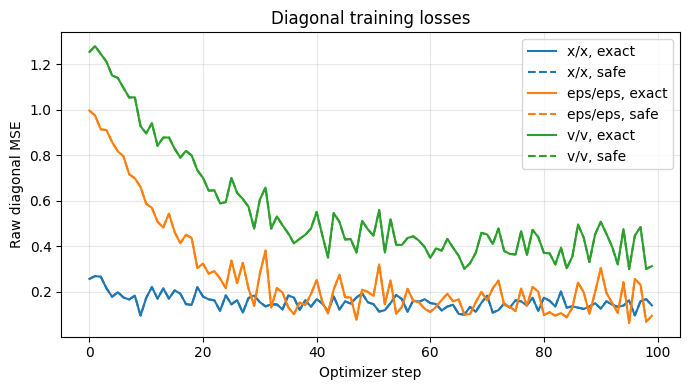

x/x: first=0.255934, last=0.139211, paired_loss_delta=0.000e+00
eps/eps: first=0.996767, last=0.093361, paired_loss_delta=0.000e+00
v/v: first=1.255153, last=0.312184, paired_loss_delta=0.000e+00


In [8]:
# Purpose: Plot the six diagonal training-loss trajectories.
loss_figure, loss_axis = plt.subplots(figsize=(7, 4))
colors = {"x": "tab:blue", "eps": "tab:orange", "v": "tab:green"}
for space in SPACES:
    for mode, line_style in (("exact", "-"), ("safe", "--")):
        loss_axis.plot(
            training_records[space][mode],
            color=colors[space],
            linestyle=line_style,
            label=f"{space}/{space}, {mode}",
        )
loss_axis.set_xlabel("Optimizer step")
loss_axis.set_ylabel("Raw diagonal MSE")
loss_axis.set_title("Diagonal training losses")
loss_axis.legend()
loss_axis.grid(alpha=0.3)
loss_figure.tight_layout()
loss_figure.savefig(RUN_DIR / "diagonal_training_losses.png", dpi=150, bbox_inches="tight")
plt.show()

for space in SPACES:
    print(
        f"{space}/{space}: first={training_records[space]['exact'][0]:.6f}, "
        f"last={training_records[space]['exact'][-1]:.6f}, "
        f"paired_loss_delta={training_pair_deltas[space]['loss_max_abs']:.3e}"
    )

In [9]:
# Purpose: Cross the training and sampling safe-division flags.
sample_tensors = {}
sample_records = []
inference_pair_deltas = {space: {} for space in SPACES}
training_sample_deltas = {space: {} for space in SPACES}

for space in SPACES:
    for training_mode, training_use_safe_div in SAFE_DIVISION_MODES:
        cfg = clone_config(base_cfg)
        cfg.framework.prediction_space = space
        cfg.framework.loss_space = space
        cfg.training.use_safe_div = training_use_safe_div

        model = GDFM(cfg).to(device)
        state = torch.load(
            RUN_DIR / f"{space}_{space}" / training_mode / "checkpoint_0100.pt",
            map_location="cpu",
            weights_only=True,
        )
        model.load_state_dict(state)
        model.eval()

        for sampling_mode, sampling_use_safe_div in SAFE_DIVISION_MODES:
            cfg.sampling.use_safe_div = sampling_use_safe_div
            samples = model.sample(
                z_init.to(device),
                n_steps=int(cfg.sampling.n_steps),
                method=str(cfg.sampling.method),
                start_time=float(cfg.sampling.start_time),
                end_time=float(cfg.sampling.end_time),
                use_safe_div=bool(cfg.sampling.use_safe_div),
                safe_div_denominator_floor=SAFE_DIV_DENOM_EPS,
                output=str(cfg.sampling.output),
                device=device,
            ).cpu()
            assert torch.isfinite(samples).all()

            sample_key = (space, training_mode, sampling_mode)
            sample_tensors[sample_key] = samples
            sample_path = (
                RUN_DIR
                / f"samples_{space}_train-{training_mode}_sample-{sampling_mode}.pt"
            )
            torch.save(samples, sample_path)

            train_metrics = compute_image_memorization_metrics(
                samples,
                train_tensor,
                encoder=None,
                rho=0.5,
                query_batch_size=N_SAMPLES,
                image_range="-1_1",
                device="cpu",
            )
            reference_metrics = compute_image_memorization_metrics(
                samples,
                reference_tensor,
                encoder=None,
                rho=0.5,
                query_batch_size=N_SAMPLES,
                image_range="-1_1",
                device="cpu",
            )

            sample_records.append(
                {
                    "space": space,
                    "training_use_safe_div": training_use_safe_div,
                    "sampling_use_safe_div": sampling_use_safe_div,
                    "sampling_output": str(cfg.sampling.output),
                    "sample_min": float(samples.min()),
                    "sample_max": float(samples.max()),
                    "sample_rms": float(samples.square().mean().sqrt()),
                    "train_f_mem": train_metrics["f_mem"],
                    "train_mean_r": train_metrics["mean_r"],
                    "reference_f_mem": reference_metrics["f_mem"],
                    "reference_mean_r": reference_metrics["mean_r"],
                }
            )

        exact_samples = sample_tensors[(space, training_mode, "exact")]
        safe_samples = sample_tensors[(space, training_mode, "safe")]
        inference_pair_deltas[space][training_mode] = {
            "rmse": float((safe_samples - exact_samples).square().mean().sqrt()),
            "max_abs": float((safe_samples - exact_samples).abs().max()),
        }

        del model
        if device.type == "mps":
            torch.mps.empty_cache()

    for sampling_mode, _ in SAFE_DIVISION_MODES:
        exact_samples = sample_tensors[(space, "exact", sampling_mode)]
        safe_samples = sample_tensors[(space, "safe", sampling_mode)]
        training_sample_deltas[space][sampling_mode] = {
            "rmse": float((safe_samples - exact_samples).square().mean().sqrt()),
            "max_abs": float((safe_samples - exact_samples).abs().max()),
        }

assert inference_pair_deltas["v"]["exact"]["max_abs"] == 0.0
print("sampling-flag safe-minus-exact deltas:", inference_pair_deltas)
print("training-flag safe-minus-exact sample deltas:", training_sample_deltas)

sampling-flag safe-minus-exact deltas: {'x': {'exact': {'rmse': 0.0, 'max_abs': 0.0}, 'safe': {'rmse': 0.0, 'max_abs': 0.0}}, 'eps': {'exact': {'rmse': 0.0, 'max_abs': 0.0}, 'safe': {'rmse': 0.0, 'max_abs': 0.0}}, 'v': {'exact': {'rmse': 0.0, 'max_abs': 0.0}, 'safe': {'rmse': 0.0, 'max_abs': 0.0}}}
training-flag safe-minus-exact sample deltas: {'x': {'exact': {'rmse': 0.0, 'max_abs': 0.0}, 'safe': {'rmse': 0.0, 'max_abs': 0.0}}, 'eps': {'exact': {'rmse': 0.0, 'max_abs': 0.0}, 'safe': {'rmse': 0.0, 'max_abs': 0.0}}, 'v': {'exact': {'rmse': 0.0, 'max_abs': 0.0}, 'safe': {'rmse': 0.0, 'max_abs': 0.0}}}


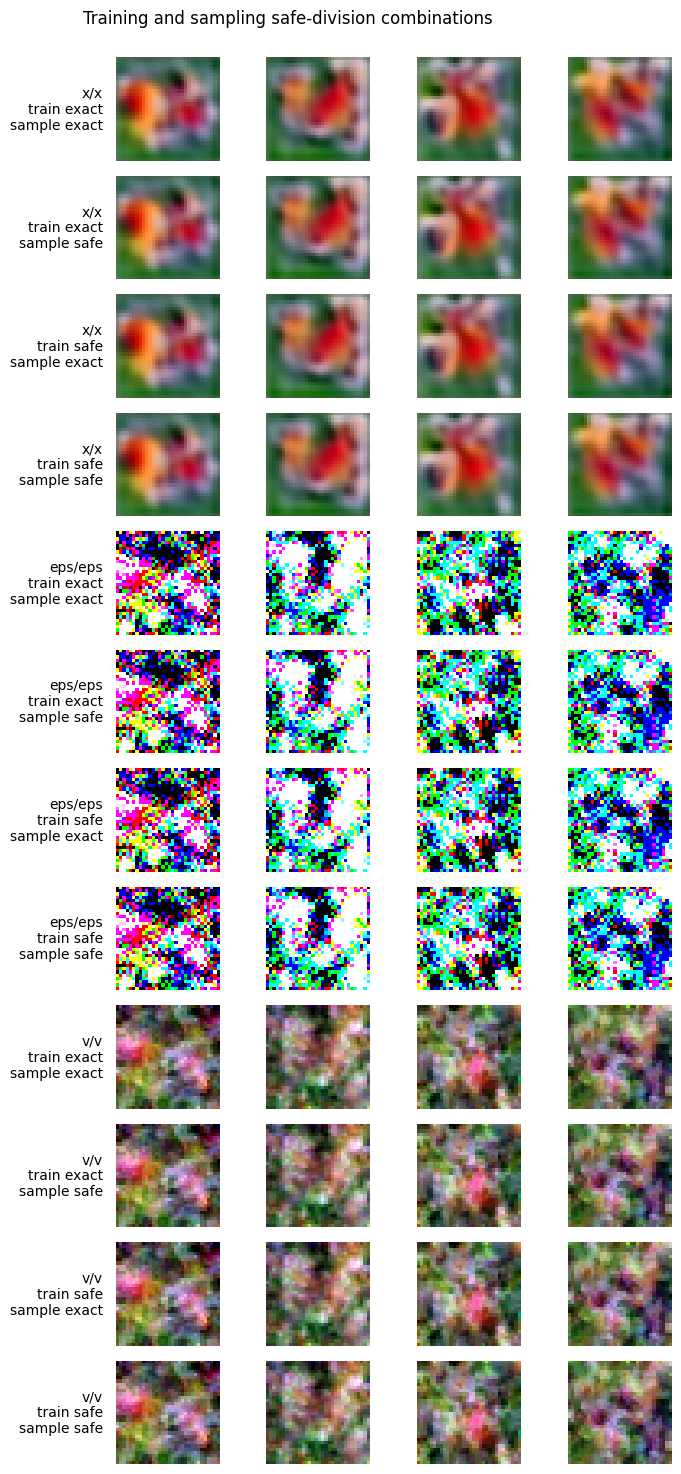

In [10]:
# Purpose: Compare all training and sampling safe-division combinations.
row_keys = tuple(
    (space, training_mode, sampling_mode)
    for space in SPACES
    for training_mode, _ in SAFE_DIVISION_MODES
    for sampling_mode, _ in SAFE_DIVISION_MODES
)
sample_figure, sample_axes = plt.subplots(len(row_keys), 4, figsize=(9, 15))

for row, (space, training_mode, sampling_mode) in enumerate(row_keys):
    sample_key = (space, training_mode, sampling_mode)
    images = sample_tensors[sample_key][:4].add(1.0).div(2.0).clamp(0.0, 1.0)
    for column in range(4):
        sample_axes[row, column].imshow(images[column].permute(1, 2, 0))
        sample_axes[row, column].axis("off")
    # Keep the condition label visible after all image axes are disabled.
    sample_axes[row, 0].text(
        -0.12,
        0.5,
        f"{space}/{space}\ntrain {training_mode}\nsample {sampling_mode}",
        transform=sample_axes[row, 0].transAxes,
        ha="right",
        va="center",
    )

sample_figure.suptitle("Training and sampling safe-division combinations")
sample_figure.tight_layout(rect=(0.16, 0.0, 1.0, 0.98))
sample_figure.savefig(RUN_DIR / "paired_samples.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Purpose: Save the result records and state the numerical conclusions.
results = {
    "protocol": protocol,
    "training_pair_deltas": training_pair_deltas,
    "training_seconds": training_seconds,
    "training_losses": training_records,
    "inference_pair_deltas": inference_pair_deltas,
    "training_sample_deltas": training_sample_deltas,
    "sample_records": sample_records,
    "conversion_summary": conversion_summary,
}
(RUN_DIR / "results.json").write_text(
    json.dumps(results, indent=2) + "\n",
    encoding="utf-8",
)

print("Training conclusion: all six labeled training runs finished.")
print("Inspect training_pair_deltas for the exact-safe training comparison.")
print("Sampling conclusion: all training and sampling flag combinations finished.")
print("Inspect both delta records to separate training and sampling effects.")
print(f"saved results: {RUN_DIR / 'results.json'}")
sample_records

Training conclusion: all six labeled training runs finished.
Inspect training_pair_deltas for the exact-safe training comparison.
Sampling conclusion: all training and sampling flag combinations finished.
Inspect both delta records to separate training and sampling effects.
saved results: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/experiments/safe_division_diagonal_sanity/results.json


[{'space': 'x',
  'training_use_safe_div': False,
  'sampling_use_safe_div': False,
  'sampling_output': 'x_t_max',
  'sample_min': -1.3872509002685547,
  'sample_max': 1.1135938167572021,
  'sample_rms': 0.4258670508861542,
  'train_f_mem': 0.0,
  'train_mean_r': 0.978000283241272,
  'reference_f_mem': 0.0,
  'reference_mean_r': 0.9622550010681152},
 {'space': 'x',
  'training_use_safe_div': False,
  'sampling_use_safe_div': True,
  'sampling_output': 'x_t_max',
  'sample_min': -1.3872509002685547,
  'sample_max': 1.1135938167572021,
  'sample_rms': 0.4258670508861542,
  'train_f_mem': 0.0,
  'train_mean_r': 0.978000283241272,
  'reference_f_mem': 0.0,
  'reference_mean_r': 0.9622550010681152},
 {'space': 'x',
  'training_use_safe_div': True,
  'sampling_use_safe_div': False,
  'sampling_output': 'x_t_max',
  'sample_min': -1.3872509002685547,
  'sample_max': 1.1135938167572021,
  'sample_rms': 0.4258670508861542,
  'train_f_mem': 0.0,
  'train_mean_r': 0.978000283241272,
  'reference